# 01 — EDA
**Pergunta deste notebook:** o que está partido nestes dados?

Trabalha sobre `anuncios_completo.csv`, que é o dataset **por limpar**. É de
propósito: só se vê o que está mal olhando para os dados sujos.

No fim há uma lista de problemas encontrados. É essa lista que o `02_limpeza`
vai resolver.

## Setup

In [2]:
import sys
sys.path.insert(0, "..")   # para poder importar de src/
import warnings, json, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", 60)
DROP_COLS   = ["ad_id","slug",'url','titulo']

from src.config import INTERIM

df = pd.read_csv(INTERIM / "anuncios_completo.csv")
print(f"{len(df)} anúncios, {df.shape[1]} colunas")

1548 anúncios, 58 colunas



## 1. Sobre o dataset 

In [4]:

#desordenar linhas
df = df.sample(frac=1).reset_index(drop=True)
df.head(50)

,ad_id,slug,url,titulo,pesquisa,preco_eur,preco_oculto,area_m2,preco_m2,preco_m2_site,tipologia,divisoes_raw,piso,piso_raw,tipo_imovel,transacao,data_publicacao,data_republicacao,agencia,agencia_id,particular,promovido,origem,n_fotos,tags,distrito,distrito_id,concelho,concelho_id,freguesia,freguesia_id,bairro,bairro_id,suspeito_tipo_errado,suspeito_arrendamento,lat,lon,raio_precisao_m,estado_anuncio,data_modificacao,n_casas_banho,extras,seguranca,descricao,ano_construcao,certificado_energetico,estado_conservacao,tipo_edificio,n_pisos_edificio,aquecimento,tipo_janelas,mercado,erro,dist_universidade_km,dist_solum_km,dist_huc_km,dist_polo_mais_proximo_km,distancia_exacta
0,19249296,t3-1-com-terraco-privativo-nos-olivais-ID1iLCv,https://www.imovirtual.com/pt/anuncio/t3-1-com...,T3 + 1 com terraço privativo nos Olivais,apartamento_santo_antonio_olivais,348500.0,False,94.00,3707.45,3707.45,T3,FOUR,NaN,NaN,FLAT,SELL,2026-08-18T23:51:19Z,2026-08-18 23:51:32,Miguel,NaN,False,False,urn:partner:olxpt,8,NaN,Coimbra,coimbra,Coimbra,coimbra/coimbra,Santo António dos Olivais,coimbra/coimbra/santo-antonio-dos-olivais,Olivais,coimbra/coimbra/santo-antonio-dos-olivais/olivais,False,False,40.216320,-8.397416,100.0,active,2026-08-18T22:51:32Z,2.0,NaN,NaN,T3+1 com Terraço Privativo e Garagem Fechada –...,NaN,d,NaN,NaN,NaN,NaN,NaN,secondary,NaN,2.661,1.463,1.418,1.418,False
1,19228662,apartamento-t2com-garagem-em-zona-do-vale-das-...,https://www.imovirtual.com/pt/anuncio/apartame...,Apartamento T2com garagem em zona do Vale das ...,apartamento_santo_antonio_olivais,475000.0,False,90.00,5277.78,5277.78,T2,THREE,NaN,NaN,FLAT,SELL,2026-07-30T17:40:23Z,2026-07-30 17:40:24,ERA Universitária,3242396.0,False,False,urn:partner:centralimo,10,AIR_CONDITIONING|GARDEN,Coimbra,coimbra,Coimbra,coimbra/coimbra,Santo António dos Olivais,coimbra/coimbra/santo-antonio-dos-olivais,Casa Branca,coimbra/coimbra/santo-antonio-dos-olivais/casa...,False,False,40.195970,-8.400380,0.0,active,2026-07-30T16:40:24Z,NaN,air_conditioning|garden,entryphone,Localizado numa das zonas mais procuradas e va...,2013.0,aplus,ready_to_use,NaN,NaN,gas,NaN,secondary,NaN,2.557,0.893,2.972,0.893,True
2,19185912,apartamento-t2-para-venda-ID1iw8c,https://www.imovirtual.com/pt/anuncio/apartame...,Apartamento T2 para venda,apartamento_coimbra_centro,330000.0,False,81.00,4074.07,4074.07,T2,THREE,0.0,GROUND,FLAT,SELL,2026-06-20T16:07:40Z,2026-06-20 16:07:48,Remax Best Selection,4006522.0,False,False,urn:partner:maxwork,8,PARKING_SPOT|GROUND_FLOOR,Coimbra,coimbra,Coimbra,coimbra/coimbra,"Sé Nova, Santa Cruz, Almedina e São Bartolomeu",coimbra/coimbra/se-nova-santa-cruz-almedina-e-...,Pedrulha,coimbra/coimbra/se-nova-santa-cruz-almedina-e-...,False,False,40.245213,-8.445370,0.0,active,2026-06-21T14:08:01Z,2.0,lift|garage,NaN,"O Cerne Residence nasce na Pedrulha, em Coimbr...",2027.0,exempt,NaN,NaN,NaN,NaN,NaN,secondary,NaN,4.499,5.859,3.855,3.855,True
3,19109783,apartamento-t2-para-venda-ID1ibkj,https://www.imovirtual.com/pt/anuncio/apartame...,Apartamento T2 para venda,apartamento_santo_antonio_olivais,310000.0,False,77.16,4017.63,4017.63,T2,THREE,1.0,FIRST,FLAT,SELL,2026-04-11T12:11:24Z,2026-04-11 12:11:32,Grupo Remax White,4133469.0,False,False,urn:partner:maxwork,5,TOP_FLOOR|PARKING_SPOT,Coimbra,coimbra,Coimbra,coimbra/coimbra,Santo António dos Olivais,coimbra/coimbra/santo-antonio-dos-olivais,Olivais,coimbra/coimbra/santo-antonio-dos-olivais/olivais,False,False,40.222824,-8.402966,0.0,active,2026-04-12T10:09:24Z,2.0,lift|garage,NaN,Apartamento T2 - GREEN LIVING \n\nEdifício de ...,2026.0,exempt,NaN,NaN,1.0,NaN,NaN,secondary,NaN,2.633,2.115,0.878,0.878,True
4,19249879,moradia-t7-rua-antero-de-quental-coimbra-ID1iLLW,https://www.imovirtual.com/pt/anuncio/moradia-...,"Moradia T7 | Rua Antero de Quental, Coimbra",moradia_coimbra_centro,700000.0,False,180.00,3888.89,3888.89,T7,EIGHT,NaN,NaN,HOUSE,SELL,2026-08-19T15:29:55Z,2026-08-19 15:30:05,Lux Properties - Coimbra,4120400.0,False,False,urn:partner:

### Identificação

| coluna | o que é |
|---|---|
| `ad_id` | Número único do anúncio no Imovirtual. É a chave do dataset — foi por aqui que se removeram os duplicados. |
| `slug` | Nome do anúncio no URL. Não é único: anúncios diferentes com o mesmo título geram o mesmo slug. |
| `url` | Endereço da página do anúncio. Útil para ir confirmar um caso estranho à mão. |
| `titulo` | Título escrito pelo anunciante. Texto livre, logo pouco fiável — mas é a única pista para detetar prédios e terrenos mal categorizados. |
| `pesquisa` | Qual das 10 pesquisas trouxe o anúncio (tipo + freguesia). Serve para rastrear a origem, não para analisar. |

### Preço e área

| coluna | o que é |
|---|---|
| `preco_eur` | Preço pedido, em euros. Nulo quando o anunciante escolheu esconder o preço. |
| `preco_oculto` | True se o anúncio não mostra preço. Explica os nulos em `preco_eur`. |
| `area_m2` | Área útil em m², como declarada pelo anunciante. |
| `preco_m2` | `preco_eur / area_m2`. **A métrica central do projeto** — permite comparar casas de tamanhos diferentes. |
| `preco_m2_site` | O mesmo valor que preco_m2 mas calculado pelo Imovirtual.

### Características do imóvel

| coluna | o que é |
|---|---|
| `tipologia` | T0 a T9+, no sentido português (nº de quartos). |
| `divisoes_raw` | O valor original do site, em inglês (`FOUR`). O Imovirtual conta divisões **incluindo a sala**, logo T3 = FOUR. Guardado para auditar a conversão. |
| `piso` | Andar, como número. 0 = rés do chão, -1 = cave. |
| `piso_raw` | O valor original (`SECOND`). Ausente em ~56% dos anúncios — o site simplesmente não o tem. |
| `tipo_imovel` | `FLAT` (apartamento) ou `HOUSE` (moradia). **Atenção:** é a categoria escolhida pelo anunciante, e há prédios e terrenos registados como FLAT. |
| `transacao` | Tipo de negócio. Constante (`SELL`) — só se recolheram vendas. |
| `n_casas_banho` | Número de casas de banho. O site trunca a contagem (só 3 valores distintos) — não tratar como contínua. |
| `ano_construcao` | Ano de construção do edifício. Em falta em 38% dos casos. |
| `certificado_energetico` | Classe energética (a+ a f). Presente em quase todos — das features mais completas. |
| `estado_conservacao` | Pronto a habitar, para recuperar, ou em construção. |
| `tipo_edificio` | Tipo de edifício (prédio, moradia isolada, etc.). |
| `n_pisos_edificio` | Número de andares do edifício onde está o imóvel. |
| `aquecimento` | Tipo de aquecimento. Muito incompleto (85% em falta). |
| `tipo_janelas` | Material das janelas. Muito incompleto (85% em falta). |
| `extras` | Comodidades, separadas por `\|` (ex: `balcony\|garage`). |
| `seguranca` | Equipamento de segurança, separado por `\|`. Muito incompleto. |
| `tags` | Etiquetas de destaque que o site mostra no cartão do anúncio. |
| `mercado` | `secondary` (usado) ou `primary` (novo, do promotor). |
| `descricao` | Texto do anúncio, já sem etiquetas HTML. Matéria-prima para features de texto. |

### Localização

| coluna | o que é |
|---|---|
| `distrito`, `distrito_id` | Constante (`Coimbra`). Não serve como variável. |
| `concelho`, `concelho_id` | Constante (`Coimbra`). |
| `freguesia` | Freguesia do anúncio. As 5 do âmbito, mais alguns promovidos de fora. |
| `freguesia_id` | Identificador estável (`coimbra/coimbra/...`). Preferir a este ao nome, que tem acentos. |
| `bairro` | **O nível geográfico mais fino que o site dá.** 23 valores, e a variável de localização com mais poder explicativo. |
| `bairro_id` | Identificador estável do bairro. |
| `lat`, `lon` | Coordenadas dadas pelo próprio Imovirtual. |
| `raio_precisao_m` | Precisão da coordenada: **0 = morada exacta**, 100 = o site difundiu o ponto num raio de 100 m para proteger a privacidade. |

### Anunciante e tempo

| coluna | o que é |
|---|---|
| `agencia` | Nome da agência ou do anunciante particular. |
| `agencia_id` | Número da agência. Nulo quando o vendedor é particular. |
| `particular` | True se o vendedor é particular e não agência. |
| `promovido` | True se o anúncio é pago para aparecer em destaque. |
| `origem` | Sistema de onde veio o anúncio (CRM da agência, site, etc.). |
| `n_fotos` | Número de fotografias. Pode indicar o cuidado posto no anúncio. |
| `data_publicacao` | **Data da primeira publicação.** É desta que se calcula o tempo em mercado. |
| `data_republicacao` | Data da última republicação. O site actualiza-a para o anúncio parecer recente — **não usar** como entrada no mercado. |
| `data_modificacao` | Data da última alteração ao anúncio. |
| `estado_anuncio` | Estado no site. Constante (`active`) nesta recolha. |

### Calculadas com scripts

Estas não vieram do site — foram criadas pelo pipeline.

| coluna | o que é |
|---|---|
| `suspeito_tipo_errado` | True quando o título contradiz a categoria — prédios, terrenos e lotes registados como apartamento.|
| `suspeito_arrendamento` | True quando o título sugere arrendamento apesar de a pesquisa ser de venda. |
| `dist_universidade_km` | Distância em linha reta à Universidade. |
| `dist_solum_km` | Distância a Solum, o centro comercial moderno. |
| `dist_huc_km` | Distância aos Hospitais da Universidade, em Celas. |
| `dist_polo_mais_proximo_km` | A menor das três acima. calculado por min(universidade, solum, huc) |
| `distancia_exacta` | True se a distância veio de coordenada exacta (`raio_precisao_m == 0`).|
| `erro` | Coluna vazia, resto de uma falha na junção dos detalhes. **A remover na limpeza.** |

---


### 1.1 · Inferir tipos de features

In [3]:
def overview(df):
    """Uma linha por coluna: tipo, nulos, cardinalidade, memória, exemplo."""
    n = len(df)
    linhas = []
    for c in df.columns:
        s = df[c]
        linhas.append({
            "coluna": c, "dtype": str(s.dtype),
            "n_nulos": int(s.isna().sum()), "pct_nulos": round(100*s.isna().mean(), 2),
            "n_unicos": int(s.nunique(dropna=True)),
            "pct_unicos": round(100*s.nunique(dropna=True)/max(n, 1), 2),
            "memoria_mb": round(s.memory_usage(deep=True)/1e6, 3),
            "exemplo": s.dropna().iloc[0] if s.notna().any() else None,
        })
    return pd.DataFrame(linhas).sort_values("pct_nulos", ascending=False).reset_index(drop=True)

print(f"Linhas: {len(df):,} | Colunas: {df.shape[1]} | Duplicados exatos: {df.duplicated().sum():,}")
print(f"Memória: {df.memory_usage(deep=True).sum()/1e6:.1f} MB")
overview(df)

Linhas: 1,548 | Colunas: 58 | Duplicados exatos: 0
Memória: 4.4 MB


,coluna,dtype,n_nulos,pct_nulos,n_unicos,pct_unicos,memoria_mb,exemplo
0,erro,float64,1548,100.00,0,0.00,0.013,None
1,seguranca,str,1325,85.59,32,2.07,0.018,roller_shutters
2,aquecimento,str,1321,85.34,6,0.39,0.014,electrical
3,tipo_janelas,str,1318,85.14,4,0.26,0.015,aluminium
4,n_pisos_edificio,float64,1239,80.04,11,0.71,0.013,4.0
5,piso,float64,876,56.59,11,0.71,0.013,2.0
6,piso_raw,str,874,56.46,12,0.78,0.016,SECOND
7,tipo_edificio,str,791,51.10,8,0.52,0.017,block
8,ano_construcao,float64,584,37.73,88,5.68,0.013,1983.0
9,tags,str,534,34.50,142,9.17,0.040,BALCONY|SECURE_BUILDING


**O que se vê:** 1548 anúncios, 58 features, é um dataset bastante largo é esperado que algumas irão cair como (`distrito_id`,  `concelho_id`,`estado_anuncio`...)

A deduplicação foi feita no scraper, por ad_id. 

8 features com numero de nulos superior a 50%, serão mais tarde candidatas a remover, a analisar mais á frente.

raio_precisao_m diz 0 = exacta, 100 = raio de 100 m e 500. Meio quilómetro de incerteza numa cidade do tamanho de Coimbra.

três colunas são ordinais não "strings":
- `tipologia` — T0 < T1 < T2 < ... < T9+
- `certificado_energetico` — `aplus` > `a` > `b` > ... > `g`
- `estado_conservacao` — `ready_to_use` > `to_completion` > `to_renovation`

In [4]:
def inferir_tipos(df, target, max_unicos_como_cat, drop=()):
    ignorar = set(drop) | ({target} if target else set())
    num, cat, dt = [], [], []
    for c in df.columns:
        if c in ignorar:
            continue
        s = df[c]
        if pd.api.types.is_datetime64_any_dtype(s):        dt.append(c)
        elif pd.api.types.is_bool_dtype(s):                cat.append(c)
        elif pd.api.types.is_numeric_dtype(s):
            (cat if s.nunique(dropna=True) <= max_unicos_como_cat else num).append(c)
        else:                                              cat.append(c)
    return {"numericas": num, "categoricas": cat, "datas": dt}
#max_unicos_como_cat calcular n_unicos / n_linhas < 0.05
max_unicos_como_cat = int(df.shape[0] * 0.05)
tipos = inferir_tipos(df, "preco_m2", max_unicos_como_cat, DROP_COLS)
NUM, CAT, DATAS = tipos["numericas"], tipos["categoricas"], tipos["datas"]
for k, v in tipos.items():
    print(f"{k:>12}: {v}")

   numericas: ['preco_eur', 'area_m2', 'preco_m2_site', 'agencia_id', 'lat', 'lon', 'ano_construcao', 'dist_universidade_km', 'dist_solum_km', 'dist_huc_km', 'dist_polo_mais_proximo_km']
 categoricas: ['pesquisa', 'preco_oculto', 'tipologia', 'divisoes_raw', 'piso', 'piso_raw', 'tipo_imovel', 'transacao', 'data_publicacao', 'data_republicacao', 'agencia', 'particular', 'promovido', 'origem', 'n_fotos', 'tags', 'distrito', 'distrito_id', 'concelho', 'concelho_id', 'freguesia', 'freguesia_id', 'bairro', 'bairro_id', 'suspeito_tipo_errado', 'suspeito_arrendamento', 'raio_precisao_m', 'estado_anuncio', 'data_modificacao', 'n_casas_banho', 'extras', 'seguranca', 'descricao', 'certificado_energetico', 'estado_conservacao', 'tipo_edificio', 'n_pisos_edificio', 'aquecimento', 'tipo_janelas', 'mercado', 'erro', 'distancia_exacta']
       datas: []


**Datas** nenhuma coluna encontrada com o tipo data, as features 'data_publicacao', 'data_republicacao' foram ambas classificadas como categóricas.

**"agencia_id"** não é um numero é um identificador.

**Três colunas são multi-valor, não categorias** `tags`, `extras` e `seguranca` guardam vários valores separados por `|`.

**"Descricao" é texto livre, não categoria**

**Há pares que dizem a mesma coisa**

- `tipologia` e `divisoes_raw` 
- `piso` e `piso_raw`
- `freguesia` e `freguesia_id`, `bairro` e `bairro_id`
- `preco_m2` e `preco_m2_site` — iguais de propósito, como verificação

Só um de cada par entra num modelo.


### 1.2 · Valores em falta

,coluna,pct_nulos,max_corr_ausencia,par
0,erro,100.00,0.00,erro
1,seguranca,85.59,0.46,tipo_janelas
2,aquecimento,85.34,0.28,extras
3,tipo_janelas,85.14,0.46,seguranca
4,n_pisos_edificio,80.04,0.40,piso_raw
5,piso,56.59,1.00,piso_raw
6,piso_raw,56.46,1.00,piso
7,tipo_edificio,51.10,0.40,piso
8,ano_construcao,37.73,0.31,n_pisos_edificio
9,tags,34.50,0.82,extras


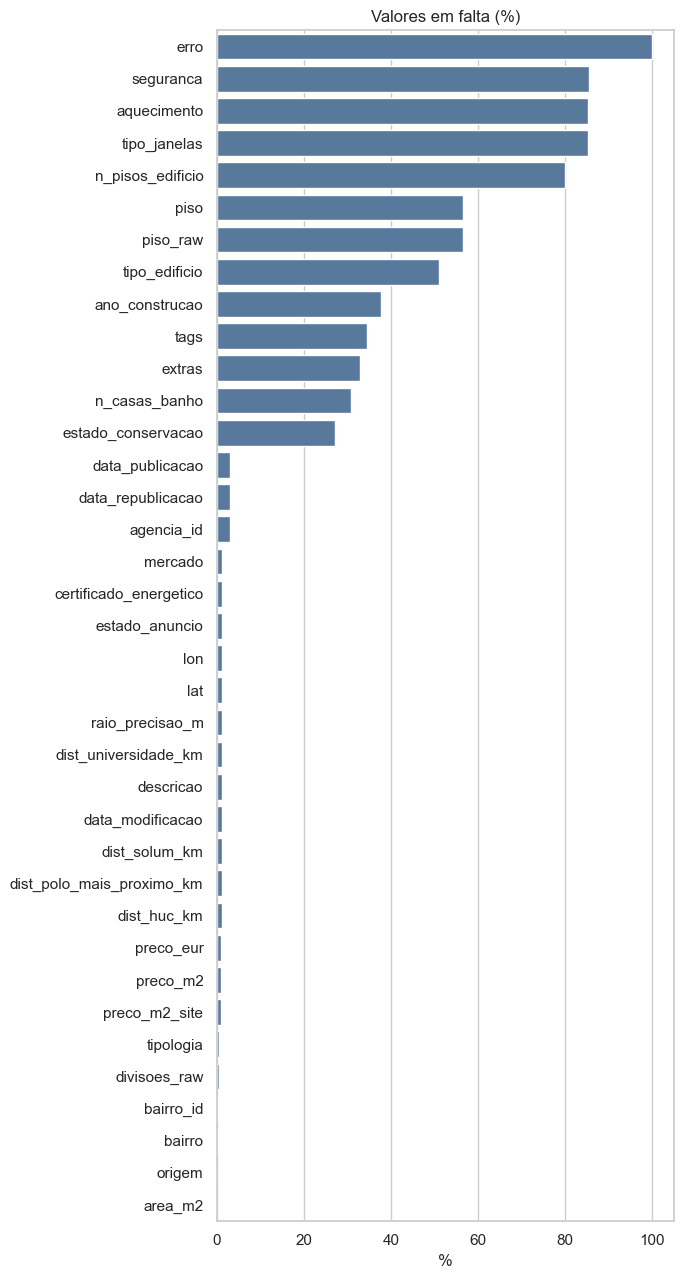

In [5]:
def relatorio_nulos(df):
    miss = (100*df.isna().mean()).sort_values(ascending=False)
    miss = miss[miss > 0].rename("pct_nulos").to_frame().round(2)
    if len(miss) > 1:
        ind = df[list(miss.index)].isna().astype(int)
        corr = ind.corr().abs()
        v = corr.to_numpy(copy=True); np.fill_diagonal(v, 0.0)
        corr = pd.DataFrame(v, index=corr.index, columns=corr.columns)
        miss["max_corr_ausencia"] = corr.max().round(2)
        miss["par"] = corr.idxmax()
    return miss.rename_axis("coluna").reset_index()

nulos = relatorio_nulos(df)
display(nulos)

if len(nulos):
    fig, ax = plt.subplots(figsize=(7, max(2.2, .35*len(nulos))))
    sns.barplot(x="pct_nulos", y="coluna", data=nulos, color="#4C78A8", ax=ax)
    ax.set_title("Valores em falta (%)"); ax.set_xlabel("%"); ax.set_ylabel("")
    plt.tight_layout(); plt.show()
else:
    print("Sem valores em falta.")


`lat`, `lon`, `raio_precisao_m`, todas as distâncias, `descricao`,
`estado_anuncio` e `data_modificacao` faltam **exactamente nas mesmas 18 linhas de 1548 (1,2%)**,o anuncio ter deixado de estar ativo enquanto se corria o scraper dos detalhes, possivel confirmar em "detalhes_cache.jsonl".

`seguranca`(85,6%), `aquecimento` (85,3%), `tipo_janelas` (85,1%),
`n_pisos_edificio` (80%), `tipo_edificio` (51%), `ano_construcao` (37,7%)
por escolha do anunciante.

`preco_eur`, `preco_m2` e `preco_m2_site` faltam juntos. A coluna  `preco_oculto` explica-o: o anunciante escolheu não mostrar preço.

`data_publicacao` e `data_republicacao` faltam juntas.

### 1.3 · Cardinalidade das categóricas

In [6]:
def relatorio_cardinalidade(df, categoricas):
    n, linhas = len(df), []
    for c in categoricas:
        vc = df[c].astype("object").value_counts(dropna=True)
        k = int(vc.size)
        risco = ("constante — remover" if k <= 1 else
                 "quase-ID — suspeito"  if k >= .9*n else
                 "alta — evitar one-hot puro" if k > 50 else "ok")
        linhas.append({"coluna": c, "cardinalidade": k,
                       "top": vc.index[0] if k else None,
                       "pct_top": round(100*vc.iloc[0]/n, 2) if k else np.nan,
                       "pct_cat_raras(<1%)": round(100*(vc/n < .01).mean(), 1) if k else np.nan,
                       "risco": risco})
    return pd.DataFrame(linhas).sort_values("cardinalidade", ascending=False).reset_index(drop=True)

relatorio_cardinalidade(df, CAT)

,coluna,cardinalidade,top,pct_top,pct_cat_raras(<1%),risco
0,data_publicacao,1426,2026-03-10T19:01:14Z,0.26,100.0,quase-ID — suspeito
1,data_modificacao,1413,2026-07-26T23:40:10Z,0.32,100.0,quase-ID — suspeito
2,data_republicacao,1345,2026-06-08 11:44:33,0.45,100.0,alta — evitar one-hot puro
3,descricao,1224,Les Terrasses\n\nViver com Vista na Quinta das...,1.16,99.8,alta — evitar one-hot puro
4,extras,207,garage,7.88,95.7,alta — evitar one-hot puro
5,tags,142,PARKING_SPOT,11.82,90.8,alta — evitar one-hot puro
6,agencia,139,Grupo Remax White,17.51,84.2,alta — evitar one-hot puro
7,n_fotos,59,11,6.20,44.1,alta — evitar one-hot puro
8,seguranca,32,anti_burglary_door|entryphone,4.20,90.6,ok
9,bairro_id,23,coimbra/coimbra/santa-clara-e-castelo-viegas/s...,23.39,26.1,ok


**As datas** aparecem com cardinalidades altas, o que é esperado, seria totalmente posivel haver uma data diferente para cada linha. A solução é converte-las para datetime.

As constantes - Remover (`erro`, `estado_anuncio`, `concelho_id`, `concelho`, `distrito_id`, `distrito`, `transacao`).

**`extras`, `tags` e `seguranca`: a cardinalidade está inflacionada**
A tabela conta *combinações*, não valores. Será necesssário expandir em colunas binárias.

**`descricao` (1224): não é categórica de todo**

**`agencia` (139): alta cardinalidade** uma boa candidata a agrupar!

**`pesquisa` (10):Aparece com cardinalidade 10** é um metadado da recolha




### 1.4 · Assimetria e outliers

In [7]:
def relatorio_distribuicoes(df, numericas):
    linhas = []
    for c in numericas:
        s = pd.to_numeric(df[c], errors="coerce").dropna()
        if s.empty or s.nunique() < 2:
            continue
        sk = float(stats.skew(s))
        sugestao = ("aproximadamente simétrica" if abs(sk) < .5 else
                    "log1p / Yeo-Johnson" if sk >= .5 and s.min() >= 0 else "Yeo-Johnson")
        linhas.append({"coluna": c, "media": s.mean(), "mediana": s.median(), "std": s.std(),
                       "min": s.min(), "p01": s.quantile(.01), "p99": s.quantile(.99), "max": s.max(),
                       "assimetria": round(sk, 3), "curtose": round(float(stats.kurtosis(s)), 3),
                       "sugestao": sugestao})
    return pd.DataFrame(linhas)


def relatorio_outliers(df, numericas, k=1.5, z=3.0):
    linhas = []
    for c in numericas:
        s = pd.to_numeric(df[c], errors="coerce").dropna()
        if s.empty: continue
        q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
        lo, hi = q1 - k*iqr, q3 + k*iqr
        pct_iqr = 100*((s < lo) | (s > hi)).mean()
        med = s.median(); mad = np.median(np.abs(s - med))
        pct_mad = 100*(np.abs(.6745*(s - med)/mad) > z).mean() if mad > 0 else 0.0
        acao = ("nada a fazer" if pct_iqr == 0 else
                "investigar caso a caso" if pct_iqr < 1 else
                "RobustScaler / winsorizar" if pct_iqr < 5 else
                "cauda pesada estrutural — transformar, não remover")
        linhas.append({"coluna": c, "lim_inf": round(lo, 2), "lim_sup": round(hi, 2),
                       "pct_out_IQR": round(pct_iqr, 2), "pct_out_MAD": round(float(pct_mad), 2),
                       "acao": acao})
    return pd.DataFrame(linhas).sort_values("pct_out_IQR", ascending=False).reset_index(drop=True)

display(relatorio_distribuicoes(df, NUM))
display(relatorio_outliers(df, NUM))

,coluna,media,mediana,std,min,p01,p99,max,assimetria,curtose,sugestao
0,preco_eur,4.554739e+05,4.100000e+05,3.028863e+05,800.000000,65930.000000,1.400000e+06,7.450000e+06,9.253,188.262,log1p / Yeo-Johnson
1,area_m2,3.369412e+02,1.080000e+02,5.031649e+03,18.000000,30.885200,6.695400e+02,1.390000e+05,27.147,743.898,log1p / Yeo-Johnson
2,preco_m2_site,3.936308e+03,3.961210e+03,1.629002e+03,3.090000,488.001000,7.538336e+03,3.269231e+04,3.694,63.226,log1p / Yeo-Johnson
3,agencia_id,2.808213e+06,3.933052e+06,1.822214e+06,1045.000000,1094.000000,5.367999e+06,5.429021e+06,-0.627,-1.292,Yeo-Johnson
4,lat,4.020800e+01,4.020735e+01,1.692956e-02,40.157470,40.168173,4.026081e+01,4.026582e+01,0.601,1.119,log1p / Yeo-Johnson
5,lon,-8.423303e+00,-8.421866e+00,2.098564e-02,-8.496001,-8.478789,-8.392496e+00,-8.363573e+00,-0.490,-0.083,aproximadamente simétrica
6,ano_construcao,2.003990e+03,2.025000e+03,6.475951e+01,189.000000,1937.000000,2.029000e+03,2.029000e+03,-22.940,638.460,Yeo-Johnson
7,dist_universidade_km,2.295665e+00,2.284000e+00,1.234596e+00,0.133000,0.224000,6.053000e+00,6.497000e+00,0.757,0.771,log1p / Yeo-Johnson
8,dist_solum_km,2.767505e+00,2.394000e+00,1.528651e+00,0.053000,0.380150,6.993000e+00,7.956000e+00,0.801,0.269,log1p / Yeo-Johnson
9,dist_huc_km,2.773199e+00,2.715000e+00,1.360012e+00,0.192000,0.429990,6.507040e+00,7.516000e+00,0.469,-0.010,aproximadamente simétrica


,coluna,lim_inf,lim_sup,pct_out_IQR,pct_out_MAD,acao
0,area_m2,-14.95,238.25,8.79,7.37,"cauda pesada estrutural — transformar, não rem..."
1,dist_polo_mais_proximo_km,-0.89,3.83,6.99,5.36,"cauda pesada estrutural — transformar, não rem..."
2,lat,40.17,40.24,6.14,4.71,"cauda pesada estrutural — transformar, não rem..."
3,preco_eur,-55187.50,890312.50,5.61,4.57,"cauda pesada estrutural — transformar, não rem..."
4,preco_m2_site,518.72,7281.98,2.55,1.11,RobustScaler / winsorizar
5,dist_universidade_km,-1.13,5.47,2.42,1.63,RobustScaler / winsorizar
6,dist_solum_km,-1.28,6.48,2.42,2.61,RobustScaler / winsorizar
7,ano_construcao,1927.00,2087.00,0.41,42.43,investigar caso a caso
8,lon,-8.49,-8.35,0.33,0.00,investigar caso a caso
9,dist_huc_km,-1.56,7.09,0.20,0.07,investigar caso a caso


**Como ler tabela de outliers**

IQR alto, MAD alto	cauda pesada em ambos os lados

IQR alto, MAD baixo	os extremos estão concentrados de um lado

IQR baixo, MAD alto	massa muito concentrada com poucos pontos longe

ambos ~0	distribuição comportada


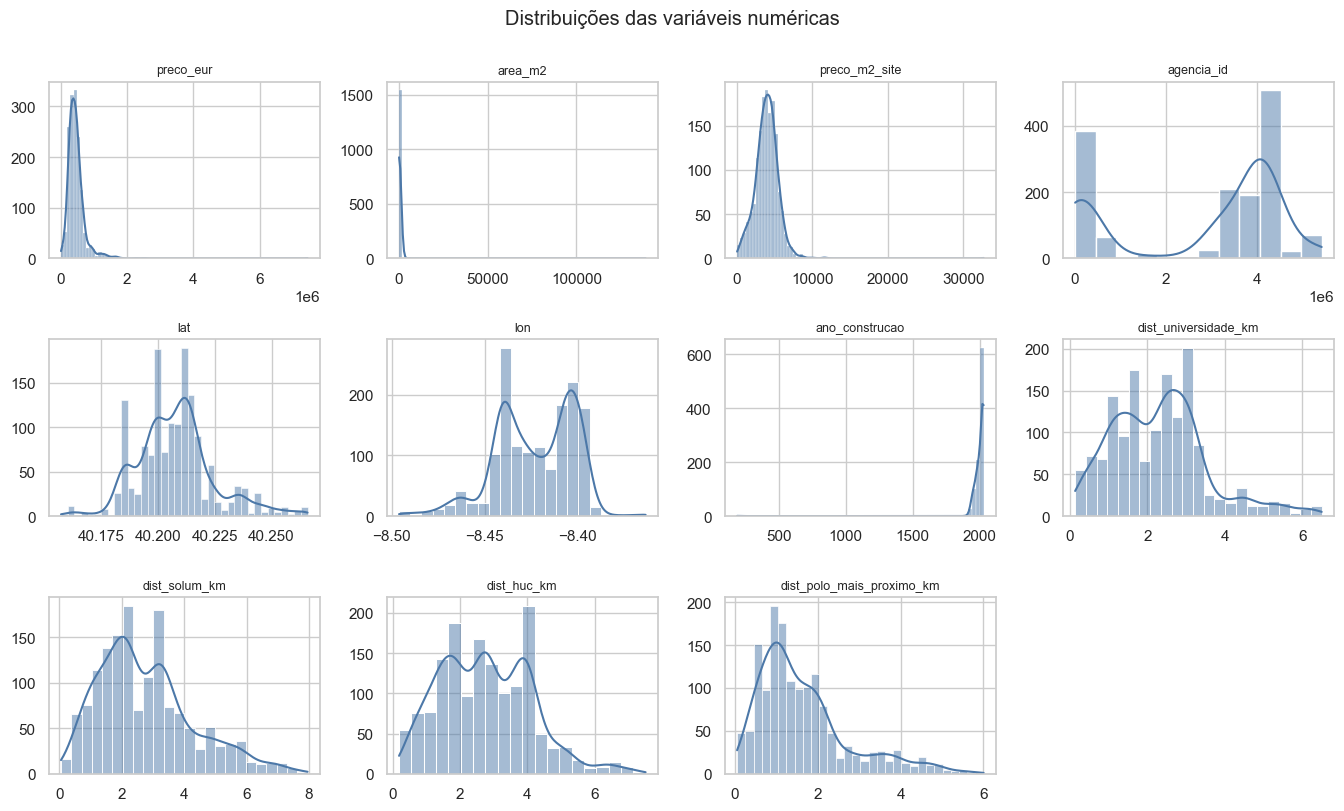

In [ ]:
def e_discreta(s, max_unicos=25):
    """True se a coluna só tem inteiros e poucos valores distintos."""
    s = pd.to_numeric(s, errors="coerce").dropna()
    return not s.empty and (s % 1 == 0).all() and s.nunique() <= max_unicos


def grelha_distribuicoes(df, cols, titulo, max_cols=24):
    cols = list(cols)[:max_cols]
    if not cols: return
    nc = min(4, len(cols)); nr = int(np.ceil(len(cols)/nc))
    fig, axes = plt.subplots(nr, nc, figsize=(3.4*nc, 2.7*nr))
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cols):
        s = pd.to_numeric(df[c], errors="coerce").dropna()
        disc = e_discreta(s)
        sns.histplot(s, kde=not disc, discrete=disc, ax=ax, color="#4C78A8")
        ax.set_title(c + ("  (discreta)" if disc else ""), fontsize=9)
        ax.set_xlabel(""); ax.set_ylabel("")
    for ax in axes[len(cols):]: ax.axis("off")
    fig.suptitle(titulo, y=1.0); plt.tight_layout(); plt.show()


grelha_distribuicoes(df, NUM, "Distribuições das variáveis numéricas")

**Distribuiçôes**

agencia_id é um identificador e lat/lon são coordenadas. Nenhuma é uma
medida, portanto média, desvio-padrão e assimetria não significam nada para
elas.

O agencia_id mostra bem porquê: em vez de uma distribuição, vêem-se dois
montes separados com um vazio entre eles. Isso não diz nada sobre imóveis —
reflecte apenas duas gamas de identificadores atribuídas pelo Imovirtual em
alturas diferentes. Uma "média de 2,8 milhões" é um número com pouco significado estatistico.

Ficam de fora da análise de distribuições. O lat e o lon já estão
representados nas colunas de distância, que essas sim são medidas.

Através da primeira coluna tambem é possivel verificar:

area_m2:	p99=670	maximo=139 000	ratio=207×

preco_m2_site:	p99=7538	maximo=32692	ratio=4×

preco_eur	p99=1,4 M	maximo=7,45 M	ratio=5×


Numa distribuição com cauda natural, o máximo fica a duas ou três vezes o
p99. Um rácio de 207 não é cauda — é outra coisa metida no meio dos dados.

É por isso que estas colunas não pedem transformação. Uma transformação
assume que os valores extremos pertencem à mesma distribuição, só que na
ponta. Aqui não pertencem.

**Outliers**



**ano de construcao valores estranhos**
ano impossível (189) - 1 
ano no futuro (2027–2029) 303
muito antigo (1892)  1 

**Preço mínimo de 800 €**

### 1.5 · Correlações

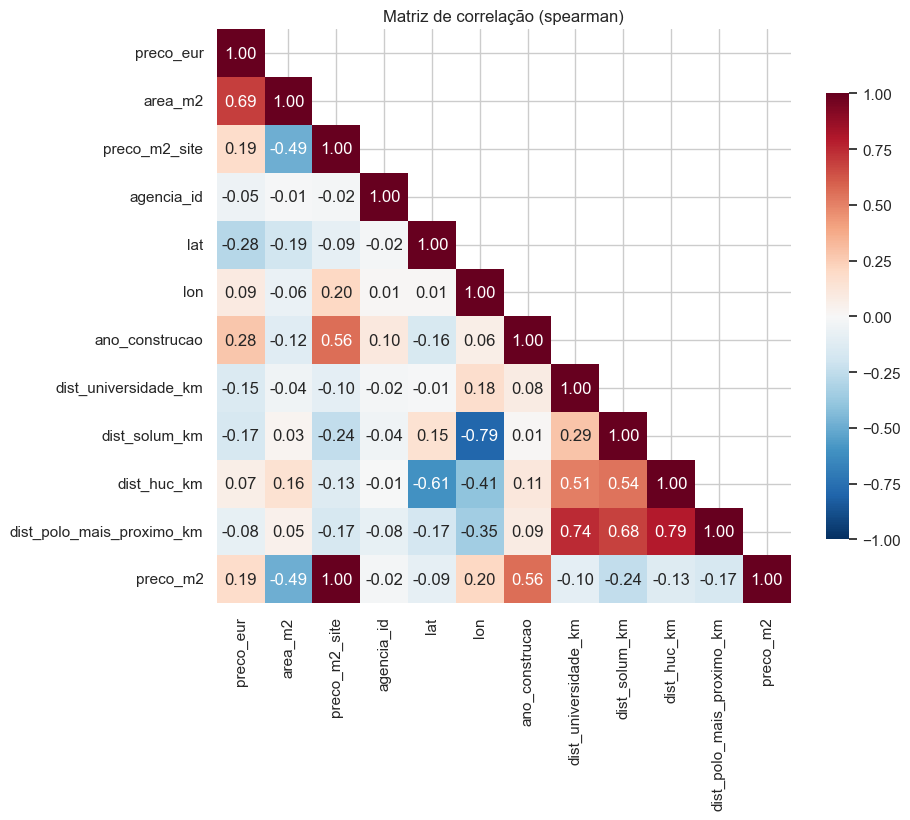

,feature_a,feature_b,corr_abs
0,preco_m2_site,preco_m2,1.0


In [9]:
def mapa_correlacao(df, cols, metodo="spearman"):
    cols = [c for c in cols if c in df.columns]
    if len(cols) < 2: return
    corr = df[cols].apply(pd.to_numeric, errors="coerce").corr(method=metodo)
    fig, ax = plt.subplots(figsize=(.55*len(cols)+3, .5*len(cols)+2.5))
    sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap="RdBu_r",
                center=0, vmin=-1, vmax=1, annot=len(cols) <= 15, fmt=".2f",
                square=True, ax=ax, cbar_kws={"shrink": .7})
    ax.set_title(f"Matriz de correlação ({metodo})"); plt.tight_layout(); plt.show()
    return corr


def pares_redundantes(corr, limiar=.85):
    m = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    p = (m.stack().rename("corr_abs").reset_index()
          .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
    return p[p["corr_abs"] >= limiar].sort_values("corr_abs", ascending=False).reset_index(drop=True)

cols_corr = NUM + ["preco_m2"]
corr = mapa_correlacao(df, cols_corr)
display(pares_redundantes(corr, .85))

n_fotos ↔ preco_m2 = −0.27, negativa. Mais fotografias associadas a preço por m² mais baixo. Não é o que se esperaria à partida.

o facto da correlaçao de preco_m2_site com preco_m2 ser 1, é a verificação cruzada a funcionar!

dist_solum_km ↔ lon e dist_huc_km ↔ lat — as distâncias foram
calculadas a partir das coordenadas.

dist_polo_mais_proximo_km ↔ as outras três — é o mínimo delas.

area_m2 ↔ preco_m2 — atenção a esta: a área está no denominador do
alvo. Parte desta correlação é matemática, não económica.


{
  "n": 1548,
  "n_nulos": 16,
  "media": 3936.308348563969,
  "mediana": 3961.21,
  "std": 1629.002498961339,
  "min": 3.09,
  "max": 32692.31,
  "assimetria": 3.694,
  "nota": "assimétrico — considera TransformedTargetRegressor(log1p)"
}


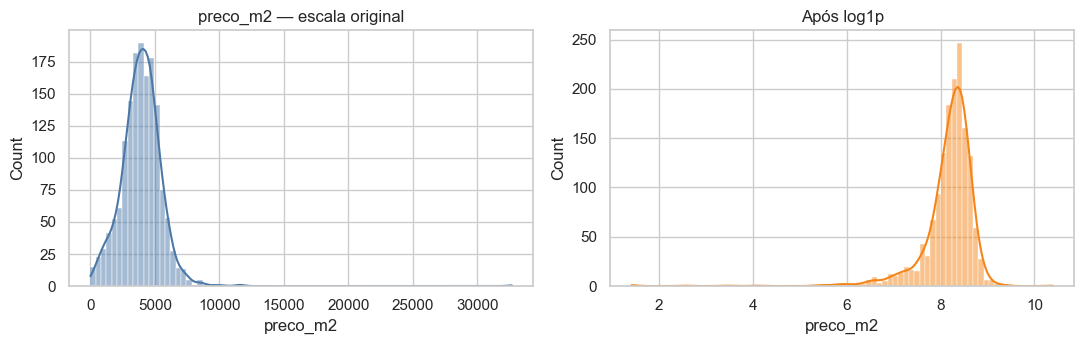

In [6]:
def relatorio_target(df, target):
    s = df[target]
    sn = pd.to_numeric(s, errors="coerce").dropna()
    sk = float(stats.skew(sn))
    info = {"n": len(s), "n_nulos": int(s.isna().sum()), "media": float(sn.mean()),
            "mediana": float(sn.median()), "std": float(sn.std()),
            "min": float(sn.min()), "max": float(sn.max()), "assimetria": round(sk, 3)}
    info["nota"] = ("assimétrico — considera TransformedTargetRegressor(log1p)"
                        if abs(sk) > 1 else "distribuição aceitável")
    return info

print(json.dumps(relatorio_target(df, "preco_m2"), indent=2, ensure_ascii=False, default=str))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
s = pd.to_numeric(df["preco_m2"], errors="coerce").dropna()
sns.histplot(s, kde=True, ax=axes[0], color="#4C78A8"); axes[0].set_title(f"preco_m2 — escala original")
sns.histplot(np.log1p(s), kde=True, ax=axes[1], color="#F58518")
axes[1].set_title("Após log1p")
plt.tight_layout(); plt.show()

O log não removeu o problema — trocou-o de lado.
Depois de limpar, é bem possível que esta variável não precise de transformação nenhuma. (se for cortado tudo a partir de 10000 o que sobra é simétrico).
A recomendação automática está a reagir aos outliers.

### 1.6 Categóricas vs alvo


In [11]:
def forca_categoricas(df, categoricas, target, min_n=10,
                      max_cardinalidade=60, ignorar=()):
    """
    Quanto da variação do alvo é explicada por cada categórica (eta²).

    Categorias com menos de `min_n` linhas são descartadas — uma mediana feita
    com 3 observações não é informação. Colunas acima de `max_cardinalidade`
    também ficam de fora: com muitas categorias o eta² sobe por acaso.
    """
    y = pd.to_numeric(df[target], errors="coerce")
    linhas = []
    for c in categoricas:
        if c in ignorar:
            continue
        sub = pd.DataFrame({"cat": df[c].astype("object"), "y": y}).dropna()
        vc = sub["cat"].value_counts()
        sub = sub[sub["cat"].isin(vc[vc >= min_n].index)]
        k = sub["cat"].nunique()
        if k < 2 or k > max_cardinalidade:
            continue

        g = sub.groupby("cat")["y"]
        media_geral = sub["y"].mean()
        ss_total = ((sub["y"] - media_geral) ** 2).sum()
        ss_entre = (g.count() * (g.mean() - media_geral) ** 2).sum()
        medianas = g.median()

        linhas.append({
            "coluna": c, "n_categorias": int(k), "n_linhas": int(len(sub)),
            "eta2": round(ss_entre / ss_total, 3) if ss_total else np.nan,
            "mediana_min": round(medianas.min()),
            "mediana_max": round(medianas.max()),
            "amplitude": round(medianas.max() - medianas.min()),
        })
    return (pd.DataFrame(linhas)
            .sort_values("eta2", ascending=False).reset_index(drop=True))


# `descricao` é texto livre — como categórica dá um valor sem significado
forca_categoricas(df, CAT, "preco_m2", ignorar=["descricao"])

,coluna,n_categorias,n_linhas,eta2,mediana_min,mediana_max,amplitude
0,estado_conservacao,3,1115,0.205,1641,4612,2972
1,pesquisa,10,1532,0.188,2017,4486,2469
2,tipo_edificio,4,734,0.167,2227,4209,1983
3,certificado_energetico,9,1513,0.166,2212,4590,2379
4,bairro,21,1518,0.150,1959,4792,2833
5,extras,15,640,0.150,3273,5305,2032
6,bairro_id,21,1518,0.150,1959,4792,2833
7,agencia,28,1300,0.145,1882,5281,3399
8,divisoes_raw,10,1519,0.144,2345,5740,3395
9,tipologia,10,1519,0.144,2345,5740,3395


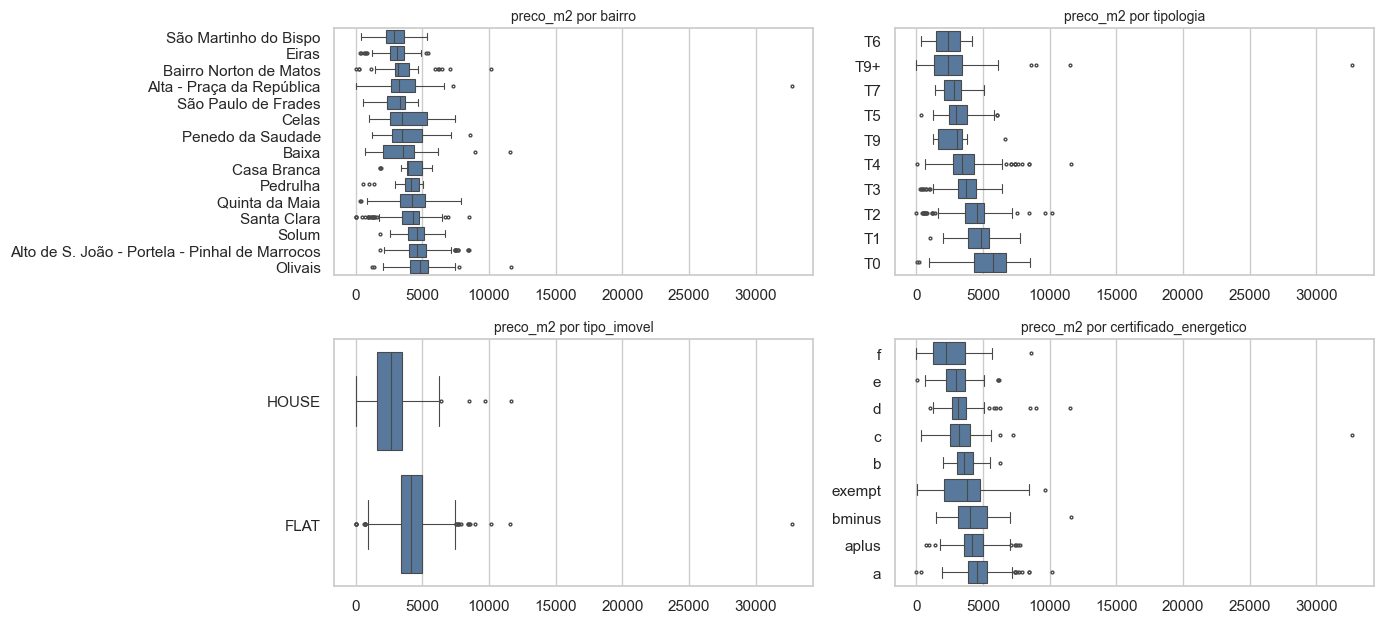

In [12]:
def grelha_categoricas(df, cols, target, min_n=10, max_cats=15):
    """Boxplot do alvo por categoria, ordenado pela mediana."""
    cols = list(cols)
    y = pd.to_numeric(df[target], errors="coerce")
    nc = min(2, len(cols)); nr = int(np.ceil(len(cols)/nc))
    fig, axes = plt.subplots(nr, nc, figsize=(7*nc, 3.2*nr))
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cols):
        sub = pd.DataFrame({"cat": df[c].astype("object"), "y": y}).dropna()
        vc = sub["cat"].value_counts()
        sub = sub[sub["cat"].isin(vc[vc >= min_n].index[:max_cats])]
        ordem = sub.groupby("cat")["y"].median().sort_values().index
        sns.boxplot(data=sub, x="y", y="cat", order=ordem, ax=ax,
                    color="#4C78A8", fliersize=2, linewidth=.8)
        ax.set_title(f"{target} por {c}", fontsize=10)
        ax.set_xlabel(""); ax.set_ylabel("")
    for ax in axes[len(cols):]: ax.axis("off")
    plt.tight_layout(); plt.show()


grelha_categoricas(df, ["bairro", "tipologia", "tipo_imovel",
                        "certificado_energetico"], "preco_m2")

A leitura do eta² tem de ser feita com o n_categorias ao lado. Uma
coluna com 30 categorias separa melhor por acaso do que uma com 3, portanto
os valores não são directamente comparáveis entre colunas de cardinalidades
muito diferentes.

pesquisa aparece em segundo lugar — e é a coluna que não pode ser usada.
Não descreve o imóvel, descreve como o recolhi: é tipo_imovel × freguesia,
ambas já presentes mais abaixo na mesma tabela. Pontuar alto era esperado.

eta² e amplitude medem coisas diferentes, e o suspeito_tipo_errado
mostra-o bem: eta² de 0,024, quase no fundo da tabela, mas amplitude de
1 665 €/m² entre os dois grupos — das maiores. Não é contradição: são 118
anúncios em 1 532, por muito diferentes que sejam movem pouco a variância
total. O eta² responde a "quanto do total isto explica", a amplitude a "quão
diferentes são os grupos".

extras e tags não estão bem medidos aqui — foram avaliados como
strings de combinação, em que garage|lift conta como categoria distinta de
garage.

Nos boxplots, duas variáveis saem com ordem monótona: a tipologia desce
de T0 para T9+, e o certificado_energetico desce de a para f. Isso
confirma que são ordinais a sério e não categorias nominais — a ordem que
lhes atribuí na 1.1 tem correspondência nos dados. As excepções são o
exempt e o bminus, que não pertencem à escala e ficam a meio.

A tipologia inverte-se em relação ao preço total: menor tipologia, maior
preço por m². É coerente com a correlação negativa entre area_m2 e
preco_m2 da secção anterior — e continua por separar quanto é efeito real
de mercado e quanto é a área estar no denominador do alvo.

### 1.7 · Features multi-valor

In [13]:
def expandir_multivalor(df, coluna, sep="|", min_n=20):
    """
    Transforma uma coluna multi-valor em colunas binárias, uma por valor.

    Só cria coluna para valores presentes em pelo menos `min_n` anúncios —
    abaixo disso é ruído.
    """
    s = df[coluna].dropna().astype(str)
    valores = sorted({v for linha in s for v in linha.split(sep)})
    listas = df[coluna].fillna("").astype(str).str.split(sep)
    out = pd.DataFrame(index=df.index)
    for v in valores:
        col = listas.apply(lambda xs: v in xs)
        if col.sum() >= min_n:
            out[f"{coluna}__{v}"] = col
    return out


def efeito_binarias(df, binarias, target, min_n=20):
    """Mediana do alvo com e sem cada característica."""
    y = pd.to_numeric(df[target], errors="coerce")
    linhas = []
    for c in binarias.columns:
        com = y[binarias[c] & y.notna()]
        sem = y[~binarias[c] & y.notna()]
        if len(com) < min_n or len(sem) < min_n:
            continue
        linhas.append({"feature": c, "n_com": int(len(com)),
                       "mediana_com": round(com.median()),
                       "mediana_sem": round(sem.median()),
                       "diferenca": round(com.median() - sem.median())})
    return (pd.DataFrame(linhas)
            .sort_values("diferenca", ascending=False).reset_index(drop=True))


bins = pd.concat([expandir_multivalor(df, c)
                  for c in ["extras", "tags", "seguranca"]], axis=1)
print(f"{bins.shape[1]} colunas binárias a partir de 3 colunas multi-valor")
display(efeito_binarias(df, bins, "preco_m2").sort_values("diferenca", ascending=False))

25 colunas binárias a partir de 3 colunas multi-valor


,feature,n_com,mediana_com,mediana_sem,diferenca
0,extras__lift,701,4480,3400,1080
1,extras__air_conditioning,429,4561,3693,868
2,extras__pool,71,4658,3901,758
3,extras__accessibility_for_people_with_reduced_...,181,4612,3867,746
4,tags__AIR_CONDITIONING,412,4465,3725,740
5,tags__POOL,51,4612,3935,677
6,seguranca__roller_shutters,55,4612,3938,675
7,seguranca__entryphone,170,4487,3882,604
8,extras__balcony,401,4306,3826,480
9,tags__SECURE_BUILDING,147,4333,3898,435


Ao expandir, várias características aparecem duas vezes com contagens quase
iguais. Não é coincidência: o tags vem do JSON da página de listagem
(item["tags"]) e o extras da página de detalhe (target["Extras_types"]).
São duas leituras do mesmo formulário que o anunciante preencheu, feitas em
momentos diferentes da recolha — uma em maiúsculas, outra em minúsculas, com
nomes nem sempre coincidentes.

As pequenas diferenças de contagem vêm de os 18 anúncios sem detalhe terem
tags mas não extras.

Decisão: manter apenas uma. O tags sobrevive aos 18 falhados; o
extras vem da página completa. A decidir no 02_limpeza.

As 25 binárias substituem 3 categóricas inúteis. Na 1.3, estas três
colunas apareciam com 207, 142 e 32 "categorias" que eram combinações. Nesta
forma são utilizáveis por um modelo.

As diferenças de mediana são
associações, não causas. Um elevador não faz uma casa valer mais — mas
edifícios com elevador são mais altos e mais recentes. O mesmo raciocínio
inverso explica os efeitos negativos: uma cozinha separada não desvaloriza um
imóvel, sinaliza construção mais antiga, quando o plano aberto ainda não era
norma.

Ou seja, várias destas binárias são provavelmente proxies da idade do
edifício — a mesma informação que o ano_construcao traz, e que tem 38% de
nulos. Vale a pena verificar essa sobreposição antes de as usar todas.

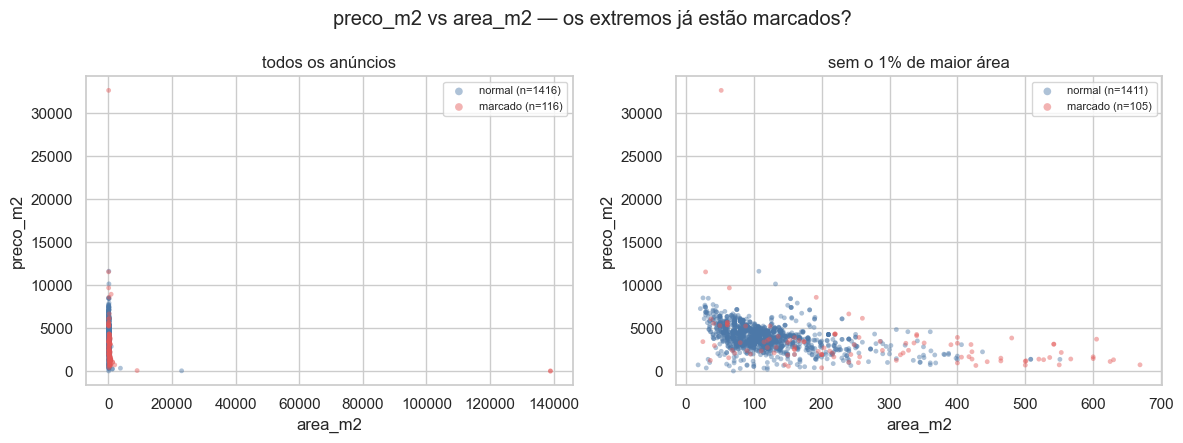

preco_m2 > 8000: 11 anúncios, dos quais já marcados: 5


In [7]:
#visualizaçao preco_m2 vs area_m2
def preco_vs_area(df, marca="suspeito_tipo_errado"):
    """
    Dispersão preço/m² contra área, separando os anúncios já marcados.

    Responde a: os extremos que vimos na 1.4 são os mesmos que a heurística do
    título já apanha, ou escapam-lhe? É o que decide se ainda é preciso um
    corte por valor no 02_limpeza.
    """
    d = df.dropna(subset=["area_m2", "preco_m2"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, zoom in zip(axes, [False, True]):
        sub = d[d.area_m2 <= d.area_m2.quantile(.99)] if zoom else d
        for flag, cor, rot in [(False, "#4C78A8", "normal"), (True, "#E45756", "marcado")]:
            m = sub[sub[marca] == flag]
            ax.scatter(m.area_m2, m.preco_m2, s=12, alpha=.45, color=cor,
                       label=f"{rot} (n={len(m)})", edgecolors="none")
        ax.set_xlabel("area_m2"); ax.set_ylabel("preco_m2")
        ax.set_title("todos os anúncios" if not zoom else "sem o 1% de maior área")
        ax.legend(fontsize=8, markerscale=1.6)
    plt.suptitle("preco_m2 vs area_m2 — os extremos já estão marcados?")
    plt.tight_layout(); plt.show()

    n_alto = (d.preco_m2 > 8000).sum()
    print(f"preco_m2 > 8000: {n_alto} anúncios, "
          f"dos quais já marcados: {d[d.preco_m2 > 8000][marca].sum()}")


preco_vs_area(df)

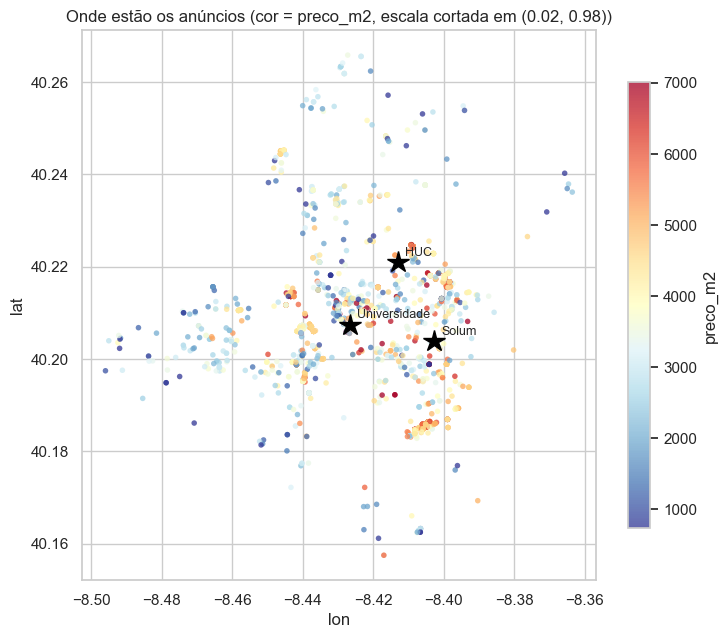

793 pontos distintos para 1514 anúncios | maior aglomerado: 44 anúncios na mesma coordenada


In [8]:
#O mapa — scatter(lon, lat) colorido por preco_m2
def mapa(df, cor="preco_m2", p=(.02, .98)):
    """
    Onde estão os anúncios, coloridos por preço/m².

    A escala de cor é cortada nos percentis para um único valor extremo não
    monopolizar o gradiente. O aspect ratio é corrigido pela latitude, senão
    a cidade aparece distorcida.
    """
    d = df.dropna(subset=["lat", "lon", cor])
    vmin, vmax = d[cor].quantile(p)
    fig, ax = plt.subplots(figsize=(7.5, 7))
    s = ax.scatter(d.lon, d.lat, c=d[cor].clip(vmin, vmax), cmap="RdYlBu_r",
                   s=16, alpha=.75, edgecolors="none", vmin=vmin, vmax=vmax)
    for nome, (la, lo) in {"Universidade": (40.2074, -8.4265),
                           "Solum": (40.2038, -8.4027),
                           "HUC": (40.2209, -8.4130)}.items():
        ax.plot(lo, la, marker="*", ms=16, color="black")
        ax.annotate(nome, (lo, la), xytext=(5, 5),
                    textcoords="offset points", fontsize=9)
    ax.set_aspect(1 / np.cos(np.radians(40.21)))
    ax.set_xlabel("lon"); ax.set_ylabel("lat")
    ax.set_title(f"Onde estão os anúncios (cor = {cor}, escala cortada em {p})")
    plt.colorbar(s, ax=ax, shrink=.7, label=cor)
    plt.tight_layout(); plt.show()

    aglom = d.groupby(["lat", "lon"]).size()
    print(f"{len(aglom)} pontos distintos para {len(d)} anúncios | "
          f"maior aglomerado: {aglom.max()} anúncios na mesma coordenada")


mapa(df)

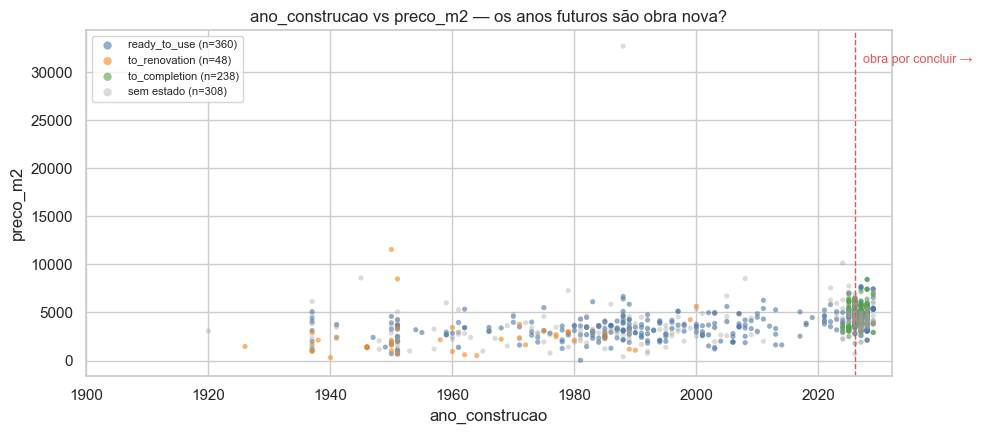

anos futuros: 302 | com estado 'to_completion': 138


In [11]:
#ano_construcao contra preco_m2
def ano_vs_preco(df, corte_futuro=2026):
    """
    Ano de construção contra preço/m², colorido pelo estado de conservação.

    Testa a hipótese da 1.4: os anos futuros são obra por concluir? Se sim,
    os pontos à direita da linha devem ser quase todos `to_completion`.
    """
    d = df.dropna(subset=["ano_construcao", "preco_m2"])
    fig, ax = plt.subplots(figsize=(10, 4.5))
    for cat, cor in zip(["ready_to_use", "to_renovation", "to_completion"],
                        ["#4C78A8", "#F58518", "#54A24B"]):
        m = d[d.estado_conservacao == cat]
        ax.scatter(m.ano_construcao, m.preco_m2, s=14, alpha=.6, color=cor,
                   label=f"{cat} (n={len(m)})", edgecolors="none")
    m = d[d.estado_conservacao.isna()]
    ax.scatter(m.ano_construcao, m.preco_m2, s=14, alpha=.35, color="#999999",
               label=f"sem estado (n={len(m)})", edgecolors="none")

    ax.axvline(corte_futuro, ls="--", color="#E45756", lw=1)
    ax.annotate("obra por concluir →", (corte_futuro, ax.get_ylim()[1] * .9),
                xytext=(6, 0), textcoords="offset points",
                fontsize=9, color="#E45756")
    ax.set_xlim(1900, 2032)          # exclui o valor impossível de 189
    ax.set_xlabel("ano_construcao"); ax.set_ylabel("preco_m2")
    ax.set_title("ano_construcao vs preco_m2 — os anos futuros são obra nova?")
    ax.legend(fontsize=8, markerscale=1.6)
    plt.tight_layout(); plt.show()

    fut = d[d.ano_construcao > corte_futuro]
    print(f"anos futuros: {len(fut)} | com estado 'to_completion': "
          f"{(fut.estado_conservacao == 'to_completion').sum()}")


ano_vs_preco(df)

## Conclusão: o que passa para o `02_limpeza`

### O que temos

**1 548 anúncios, 58 colunas** — apartamentos e moradias à venda em 5
freguesias de Coimbra, recolhidos do Imovirtual. Nenhuma limpeza aplicada.

### O que se aprendeu, em três frases

**1. Os dados estão razoavelmente completos, mas contaminados.** A maioria das
colunas essenciais está preenchida. O problema não é falta de dados — é haver
coisas no meio que não pertencem: terrenos, prédios inteiros, um arrendamento.

**2. Os valores em falta não são aleatórios.** Faltam em blocos, e cada bloco
tem uma causa identificável. Isso obriga a tratar cada bloco de forma
diferente, e desaconselha imputações automáticas.

**3. Nenhuma variável explica o preço sozinha.** O melhor preditor isolado fica
longe de chegar. Era esperado: o alvo já está normalizado pela área, ou seja
já lhe foi retirado o factor mais óbvio.

---

### Problemas a resolver no `02_limpeza`

| # | problema | quantos | decisão | secção |
|---|---|---:|---|---|
| 1 | Colunas constantes | 7 | remover | 1.3 |
| 2 | Coluna `erro`, sempre vazia | 1548 | remover | 1.2 |
| 3 | Anúncios de tipo errado (prédios, terrenos) | 118 | remover | 1.6 |
| 4 | Arrendamento numa pesquisa de venda | 1 | remover | 1.4 |
| 5 | Preço/m² acima de 8 000 que escapam à marcação | 6 | inspecionar e cortar | 1.8 |
| 6 | Preço escondido pelo anunciante | 16 | remover (sem alvo, não servem) | 1.2 |
| 7 | Sem coordenadas nem detalhe (HTTP 410) | 18 | manter, marcar como incompletos | 1.2 |
| 8 | `ano_construcao = 189` | 1 | pôr a nulo | 1.4 |
| 9 | `ano_construcao` no futuro | 302 | separar como obra nova, não idade negativa | 1.8 |
| 10 | Datas por converter | 3 col. | `pd.to_datetime` + criar `dias_em_mercado` | 1.1 |
| 11 | Colunas multi-valor | 3 col. | expandir em 25 binárias | 1.7 |
| 12 | `tags` e `extras` duplicam a informação | 2 col. | escolher uma | 1.7 |
| 13 | Pares redundantes (`piso`/`piso_raw`, etc.) | 5 pares | ficar com um de cada | 1.1 |
| 14 | `agencia` com 139 níveis | 139 | agrupar as maiores + "outras" | 1.3 |
| 15 | Bairros com poucos anúncios | 5 | agrupar ou subir a freguesia | 1.6 |

**Ordem importa:** aplicar primeiro as remoções por categoria (3 e 4) e só
depois os cortes por valor (5). Ao contrário, deixa de se poder mostrar quanto
é que a marcação por título já resolvia.

---

### Colunas que não entram no modelo, e porquê

| coluna | motivo |
|---|---|
| `pesquisa` | metadado da recolha, não do imóvel — e é `tipo × freguesia`, já presentes |
| `agencia_id` | identificador, não é medida |
| `lat`, `lon` | coordenadas — já representadas nas distâncias |
| `preco_m2_site` | duplicado do alvo; se entrar, o modelo prevê-se a si próprio |
| `preco_eur`, `area_m2` | o alvo é construído a partir delas — leakage directo |
| `ad_id`, `slug`, `url` | identificadores |
| `raio_precisao_m`, `distancia_exacta` | descrevem a qualidade da medição, não o imóvel |

O ponto mais importante desta tabela é o **`preco_eur` e o `area_m2`**: como
`preco_m2 = preco_eur / area_m2`, deixá-los entrar seria dar a resposta ao
modelo.

---

### Notas a levar, que não são problemas

- **A verificação cruzada funcionou.** `preco_m2` e `preco_m2_site` batem
  certo em todas as linhas — o preço e a área estão a ser lidos correctamente.
- **`data_republicacao` não serve para tempo em mercado.** O site actualiza-a
  para o anúncio parecer recente. Usar a `data_publicacao`.
- **As distâncias são fiáveis ao nível do bairro, não da rua.** 793 pontos
  distintos para 1 514 anúncios, com aglomerados até 44 no mesmo ponto.
- **Várias binárias são proxies da idade do edifício.** Elevador e cozinha
  aberta sinalizam construção recente. Cuidado ao usá-las junto com o
  `ano_construcao`.

---

### Perguntas que ficam em aberto

1. **Quanto da relação entre área e preço/m² é real e quanto é matemático?**
   A área está no denominador do alvo. Separar as duas coisas afecta a leitura
   da tipologia e do tipo de imóvel.
2. **Porque é que só metade dos anos futuros está marcada como obra por
   concluir?** Ou o `estado_conservacao` está mal preenchido, ou o
   `ano_construcao` é inconsistente.
3. **`estado_conservacao` é o de maior eta², mas sobrepõe-se aos suspeitos?**
   Prédios para recuperar caem naturalmente em `to_renovation`. Verificar
   depois da limpeza se o sinal se mantém.
4. **Vale a pena usar o texto da `descricao` para recuperar campos em falta?**
   Sobretudo `estado_conservacao` (27% de nulos) e `ano_construcao` (38%).

---

### Direção para a modelação

O EDA aponta para **modelos baseados em árvores**, por três razões concretas
que aqui apareceram:

- a assimetria e os outliers tornam as transformações irrelevantes, porque as
  árvores dividem por limiares;
- os valores em falta são não-aleatórios, e implementações como o
  `HistGradientBoosting` lidam com nulos nativamente, sem imputar;
- as relações não são lineares — as distâncias mostram patamares, não
  gradientes.

**A confirmar contra um baseline linear.** Se o modelo complexo não bater uma
regressão simples, não compensa a perda de interpretabilidade — e este projeto
precisa de explicar porque é que um anúncio está fora do preço, não só de
acertar.